In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
data = pd.read_excel('employee.xlsx', index_col='Serial')
data

,Emp_ID,Designation,Department,Age,Salary
Serial,,,,,
1,1101,Manager,Accounts,50.0,200000.0
2,1107,Officer,IT,30.0,80000.0
3,1203,Officer,HR,28.0,NaN
4,1005,Manager,HR,45.0,120000.0
5,2123,Office Boy,Accounts,27.0,45000.0
6,2451,Accountant,NaN,34.0,100000.0
7,1111,Accountant,Accounts,NaN,110000.0
8,1001,Officer,IT,25.0,75000.0
9,1234,Manager,IT,23.0,NaN


<Axes: ylabel='Age'>

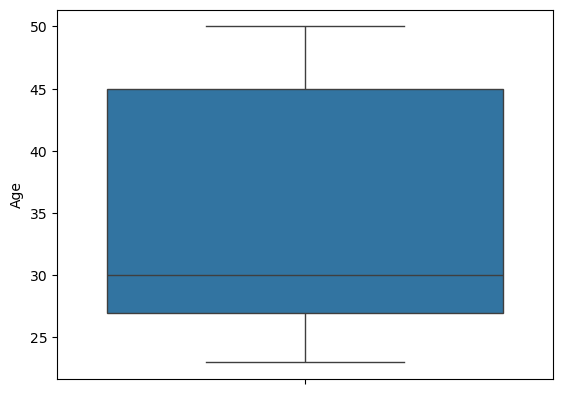

In [37]:
sns.boxplot(data.Age)

<Axes: ylabel='Salary'>

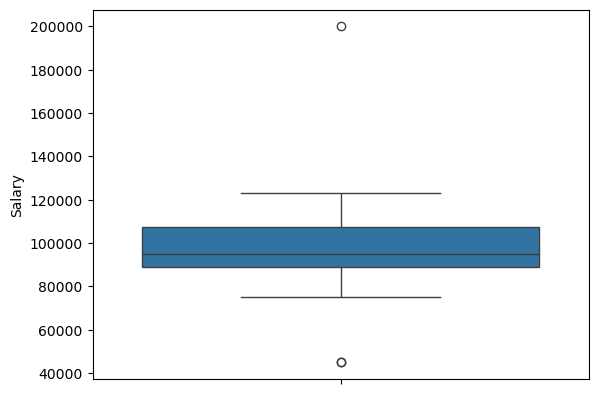

In [38]:
sns.boxplot(data.Salary)

In [39]:
data.Salary.min()
data.Salary.max()

200000.0

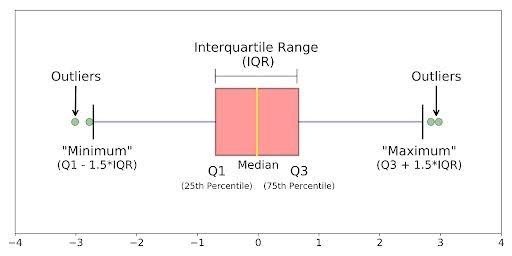!

In [40]:
def calculate_min_max_bondary(col):
    # quartile1: 25
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3-q1

    lb = q1-1.5*iqr
    ub = q3+1.5*iqr
    return lb, ub


In [41]:
calculate_min_max_bondary(data.Salary)

(61250.0, 135250.0)

In [42]:
data[((data.Salary<61250) | (data.Salary>135250 ))]

,Serial,Emp_ID,Designation,Department,Age,Salary
0,1,1101,Manager,Accounts,50.0,200000.0
4,5,2123,Office Boy,Accounts,27.0,45000.0
17,18,2123,Office Boy,Accounts,27.0,45000.0


In [43]:
data[(data.Salary<calculate_min_max_bondary(data.Salary)[0]) | (data.Salary>calculate_min_max_bondary(data.Salary)[1])]

,Serial,Emp_ID,Designation,Department,Age,Salary
0,1,1101,Manager,Accounts,50.0,200000.0
4,5,2123,Office Boy,Accounts,27.0,45000.0
17,18,2123,Office Boy,Accounts,27.0,45000.0


In [44]:
data = data[~((data.Salary<calculate_min_max_bondary(data.Salary)[0]) | (data.Salary>calculate_min_max_bondary(data.Salary)[1]))]

In [ ]:
sns.boxplot(data.Salary)

In [46]:
data.duplicated().sum()

4

In [53]:
data[data.duplicated()]

,Serial,Emp_ID,Designation,Department,Age,Salary


In [51]:
data.drop_duplicates(inplace=True)

C:\Users\Nasir Hussain\AppData\Local\Temp\ipykernel_23800\2282015914.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.drop_duplicates(inplace=True)


In [52]:
data.duplicated().sum()

0

In [73]:
data = pd.read_csv('car_data.csv')

In [74]:
data.shape

(892, 6)

In [75]:
data.head()

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel


In [76]:
data.isna().sum()

name           0
company        0
year           0
Price          0
kms_driven    52
fuel_type     55
dtype: int64

In [77]:
data.duplicated().sum()

94

In [78]:
data.drop_duplicates(inplace=True)

In [79]:
data.shape

(798, 6)

In [80]:
data.isna().sum()

name           0
company        0
year           0
Price          0
kms_driven    50
fuel_type     53
dtype: int64

# Droppping NaN values

In [81]:
data.dropna(inplace=True)

In [82]:
data.isna().sum()

name          0
company       0
year          0
Price         0
kms_driven    0
fuel_type     0
dtype: int64

In [83]:
data.reset_index(inplace=True, drop=True)

In [84]:
data

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
...,...,...,...,...,...,...
740,Maruti Suzuki Ritz VXI ABS,Maruti,2011,"2,70,000","50,000 kms",Petrol
741,Tata Indica V2 DLE BS III,Tata,2009,"1,10,000","30,000 kms",Diesel
742,Toyota Corolla Altis,Toyota,2009,"3,00,000","1,32,000 kms",Petrol
743,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel


# Data Types

In [85]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 745 entries, 0 to 744
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        745 non-null    object
 1   company     745 non-null    object
 2   year        745 non-null    object
 3   Price       745 non-null    object
 4   kms_driven  745 non-null    object
 5   fuel_type   745 non-null    object
dtypes: object(6)
memory usage: 35.1+ KB


# Name

In [ ]:
data.name.unique()

In [121]:
data.name = data.name.str.split().str[:3].str.join(' ')

In [105]:
fruit = pd.Series(['apple', 'orange', 'mango'])
fruit

0     apple
1    orange
2     mango
dtype: object

In [107]:
fruit.replace('apple','banana')

0    banana
1    orange
2     mango
dtype: object

In [109]:
fruit.str.replace('a', 'A')

0     Apple
1    orAnge
2     mAngo
dtype: object

# Year

In [119]:
data.year.unique()

array(['2007', '2006', '2018', '2014', '2015', '2012', '2013', '2016',
       '2010', '2017', '2008', '2011', '2019', '2009', '2005', '2000',
       '2003', '2004', '1995', '2002', '2001'], dtype=object)

In [122]:
data.year =  data.year.astype(int)

# Price

In [125]:
data.Price.unique()

array(['80,000', '4,25,000', 'Ask For Price', '3,25,000', '5,75,000',
       '1,75,000', '1,90,000', '8,30,000', '2,50,000', '1,82,000',
       '3,15,000', '4,15,000', '3,20,000', '10,00,000', '5,00,000',
       '3,50,000', '1,60,000', '3,10,000', '75,000', '1,00,000',
       '2,90,000', '95,000', '1,80,000', '3,85,000', '1,05,000',
       '6,50,000', '6,89,999', '4,48,000', '5,49,000', '5,01,000',
       '4,89,999', '2,80,000', '3,49,999', '2,84,999', '3,45,000',
       '4,99,999', '2,35,000', '2,49,999', '14,75,000', '3,95,000',
       '2,20,000', '1,70,000', '85,000', '2,00,000', '5,70,000',
       '1,10,000', '4,48,999', '18,91,111', '1,59,500', '3,44,999',
       '4,49,999', '8,65,000', '6,99,000', '3,75,000', '2,24,999',
       '12,00,000', '1,95,000', '3,51,000', '2,40,000', '90,000',
       '1,55,000', '6,00,000', '1,89,500', '2,10,000', '3,90,000',
       '1,35,000', '16,00,000', '7,01,000', '2,65,000', '5,25,000',
       '3,72,000', '6,35,000', '5,50,000', '4,85,000', '3,29,5

In [130]:
data = data[(data.Price!='Ask For Price')]

In [135]:
data.Price=data.Price.str.replace(',', '').astype(int)

C:\Users\Nasir Hussain\AppData\Local\Temp\ipykernel_23800\1376238901.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.Price=data.Price.str.replace(',', '').astype(int)


In [137]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 724 entries, 0 to 744
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        724 non-null    object
 1   company     724 non-null    object
 2   year        724 non-null    int32 
 3   Price       724 non-null    int32 
 4   kms_driven  724 non-null    object
 5   fuel_type   724 non-null    object
dtypes: int32(2), object(4)
memory usage: 33.9+ KB
